# Drifter-Based Ocean Current Assimilation
## Based on Issa et al. (2016)

This notebook implements a **data assimilation** workflow that corrects ocean-current background fields
using synthetic (or real) drifter trajectories.

Two assimilation strategies are provided — choose one in **Section 4**:

| Strategy | Key idea | `METHOD` value |
|---|---|---|
| **Standard (multi-window)** | `dU` is constant within each correction window | `"standard"` |
| **Sliding window** | A time-continuous `dU(t)` is reconstructed by overlapping Gaussian-weighted windows | `"sliding"` |

### Workflow overview
```
1. Preprocessing   → standardise .nc input files
2. Load fields     → extract velocity tensors for the chosen domain & period
3. Drifter seeding → simulate synthetic trajectories on the "truth" field
4. Assimilation    → choose method and run the optimisation
5. Visualisation   → quiver plots, loss curves, RMSE-time plots
```

### References
- Leila Issa, Julien Brajard, Milad Fakhri, Daniel Hayes, Laurent Mortier, and Pierre-Marie Poulain. Modelling
surface currents in the eastern levantine mediterranean using surface drifters and satellite altimetry. Ocean
Modelling, 104:1–14, 2016.

### Repository structure
```
project_root/
├── data/                   # Input .nc files and preprocessed outputs
├── output/                 # Experiment results (.h5)
└── src/
    ├── assim_nb.ipynb      # This notebook
    ├── analysis_nDrif.py   # Core assimilation engine (multi-window)
    ├── sliding_window_assim.py  # Sliding-window assimilation
    ├── reading_routines.py # NetCDF reading / scanning utilities
    └── plots.py            # Visualisation routines
```


## 0 · Imports

In [8]:
# Standard library
import time
from pathlib import Path

# Third-party
import numpy as np
import h5py
import matplotlib.pyplot as plt

## 1 · Project directories

> **Assumed project structure**  
> ```
> project_root/       ← ROOT_DIR (one level above this notebook)
> ├── data/
> └── src/            ← notebook lives here
> ```

In [9]:
# Root is one directory above the notebook's location
ROOT_DIR = Path.cwd().parent
dat_dir = ROOT_DIR / "data"
out_dir = ROOT_DIR / "output"
out_dir.mkdir(exist_ok=True)

print("ROOT_DIR :", ROOT_DIR)
print("data dir :", dat_dir)
print("output dir:", out_dir)

ROOT_DIR : /Users/anishammoud/Documents/assimilation_research_codes
data dir : /Users/anishammoud/Documents/assimilation_research_codes/data
output dir: /Users/anishammoud/Documents/assimilation_research_codes/output


## 2 · Data pre-processing

Edit the two filenames below to point to your own `.nc` files.

| Variable | Typical source | Role |
|---|---|---|
| `back_filename` | Satellite altimetry (e.g. AVISO / DUACS) | Background field |
| `truth_filename` | Ocean re-analysis (e.g. CMEMS MED-PHY) | "Truth" / observation proxy |

`preprocessing()` reprojects both datasets onto a common grid and writes
standardised files (`back_stand.nc`, `truth_stand.nc`, `truth_stand_inter.nc`)
to `dat_dir`.

In [10]:
# User input 
back_filename  = "(new_aviso)cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_1767634358778.nc"     # e.g. AVISO satellite SSH/currents
truth_filename = "(new_reanalysis)cmems_mod_med_phy-cur_my_4.2km_P1D-m_1767810181825.nc"           # e.g. CMEMS reanalysis currents

# Derived paths 
back_file  = dat_dir / back_filename
truth_file = dat_dir / truth_filename

back_stand = dat_dir / "back_stand.nc"
truth_stand = dat_dir / "truth_stand.nc"
truth_stand_inter = dat_dir / "truth_stand_inter.nc"

# ── Run preprocessing ─────────────────────────────────────────────────────────
from analysis_nDrif import preprocessing

preprocessing(truth_file, back_file, truth_stand, truth_stand_inter, back_stand)
print("Pre-processing complete.")

Pre-processing complete.


### 2b · (Optional) Inspect pre-processed files

Run this cell to verify the variables and dimensions available in the
standardised files before continuing.

In [11]:
from reading_routines import scan_file

print(f"Background  : {back_stand}")
scan_file(back_stand)

print()
print(f"Truth (interp): {truth_stand_inter}")
scan_file(truth_stand_inter)

# Note: if you use a reanalysis as truth you will see a depth dimension.
# The assimilation routines expect depth-averaged / surface-level 2-D fields.
# Depth dimension is dropped.

Background  : /Users/anishammoud/Documents/assimilation_research_codes/data/back_stand.nc
['ugos', 'm/s', (31, 128, 340)]
['vgos', 'm/s', (31, 128, 340)]
['time', 'seconds since 1970-01-01', (31,)]
['latitude', 'degrees_north', (128,)]
['longitude', 'degrees_east', (340,)]

Truth (interp): /Users/anishammoud/Documents/assimilation_research_codes/data/truth_stand_inter.nc
['ugos', 'm s-1', (31, 128, 340)]
['vgos', 'm s-1', (31, 128, 340)]
['time', 'seconds since 1970-01-01', (31,)]
['longitude', 'degrees_east', (340,)]
['latitude', 'degrees_north', (128,)]


## 3 · Load velocity fields

Extract 2-D velocity tensors for the chosen spatial domain and time window.

| Parameter | Meaning |
|---|---|
| `LON` | `[lon_min, lon_max]` in degrees East |
| `LAT` | `[lat_min, lat_max]` in degrees North |
| `start_time` | First time index to load |
| `end_time` | Last time index (exclusive) |

In [12]:
from analysis_nDrif import velocity_lon_lat

# User input 
LON = [30, 32]   # [lon_min, lon_max]  degrees East
LAT = [33, 35]   # [lat_min, lat_max]  degrees North
start_time = 0          # first time-step index
end_time = 4          # last  time-step index (exclusive)

# Load
Ut, Vt, Ub, Vb, lon, lat = velocity_lon_lat(
    LON, LAT, start_time, end_time, truth_stand_inter, back_stand
)

print(f"Truth field shape  : {Ut.shape}  (time, ny, nx)")
print(f"Background shape   : {Ub.shape}")
print(f"Lon range: {lon.min():.3f} – {lon.max():.3f}")
print(f"Lat range: {lat.min():.3f} – {lat.max():.3f}")

Truth field shape  : torch.Size([4, 16, 16])  (time, ny, nx)
Background shape   : torch.Size([4, 16, 16])
Lon range: 30.062 – 31.938
Lat range: 33.062 – 34.938


## 3b · Synthetic drifter trajectories

Drifters are advected on the **truth** velocity field to generate
synthetic observations (`synth_traj = True`).  
Replace with real drifter data by loading your own positions into the HDF5 group.

| Parameter | Meaning |
|---|---|
| `nDaysSim` | Total simulation length (days) |
| `n_drif` | Number of drifters |
| `dtAdvection` | Advection time-step (seconds) |
| `lon0`, `lat0` | Initial positions (lists of floats) |

In [13]:
from analysis_nDrif import run_onTruth_new

# User input
nDaysSim = end_time - start_time - 1            # total simulation duration (days)
n_drif = 1             # number of drifters
dtAdvection = 3600.0 / 2   # advection time-step: 30 min in seconds
lon0 = [30.3]               # initial longitude(s) — keep as list
lat0 = [34.3]               # initial latitude(s)  — keep as list

# HDF5 output file (one file per experiment) 
exp_name = "experiment_02"
mainh5 = h5py.File(out_dir / f"{exp_name}.h5", "a")
obs_grp = mainh5.require_group("metadata")

# Run 
run_onTruth_new(Ut, Vt, lon, lat, nDaysSim, obs_grp, dtAdvection, lon0, lat0, n_drif)
print("Synthetic trajectories generated and saved.")

tensor(1.6568)
Mean speed (m/s): 0.09344612807035446
Max speed (m/s): 0.20025067031383514
Min speed (m/s): 0.005126402247697115


  0%|          | 0/3 [00:00<?, ?it/s]/Users/anishammoud/Documents/assimilation_research_codes/src/multilinear.py:58: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:351.)
  numerator += self.values[as_s] * \
100%|██████████| 3/3 [00:00<00:00, 13.68it/s]

Trajectory simulated on the Truth!!
Synthetic trajectories generated and saved.


## 4 · Assimilation parameters & method selection

### 4a · Common hyper-parameters

| Parameter | Symbol | Meaning |
|---|---|---|
| `lfil` | — | Gaussian filter length-scale (m) |
| `dtObservation` | Δt_obs | Observation sampling interval (s) |
| `mylr` | η | Adam learning rate |
| `alpha` | α | Regularisation weight on ‖δU‖² |
| `beta` | β | Penalty weight on divergence |
| `n_corr` | — | Number of sequential correction windows |
| `toll` | — | Convergence tolerance on ‖∇ₓL‖ |

### 4b · Choose your assimilation strategy

Set `METHOD` to one of:

| Value | Strategy |
|---|---|
| `"standard"` | **Multi-window** — δU is constant in each window (*Issa et al. 2016*) |
| `"sliding"` | **Sliding window** — overlapping Gaussian windows reconstruct a full δU(t) |

In [14]:
# Common assimilation hyper-parameters 
lfil = 15000       # Gaussian filter half-width (m)
dtObservation = 3600.0 / 2  # observation time-step: 30 min in seconds
mylr = 0.01        # Adam learning rate
alpha = 0.001       # weight on ‖dU‖² regularisation term
beta = 0.1         # weight on divergence penalty
n_corr = 1           # number of sequential correction windows (standard only)
toll = 1.0         # convergence tolerance on relative |grad(L)|
synth_traj = True        # True: use synthetic trajectories generated in §3b

# Ocean masks (NaN → masked grid points)
u_sample = Ut[0].detach().cpu().numpy()
v_sample = Vt[0].detach().cpu().numpy()
maskuu   = np.isnan(u_sample)
maskvv   = np.isnan(v_sample)

#   USER CHOICE — set METHOD to "standard" or "sliding"
METHOD = "standard"    #  change this line

# Sliding-window-specific parameters (ignored when METHOD = "standard")
Tw_days    = 3   # window width  (days) — paper's recommended value
sigma_days = 1   # window shift  (days) — paper's recommended value

print(f"Assimilation method selected: '{METHOD}'")

Assimilation method selected: 'standard'


## 5 · Run assimilation

The cell below dispatches to the correct algorithm based on `METHOD`.

In [15]:
t0 = time.time()

if METHOD == "standard":
    # Standard multi-window assimilation 
    # dU is a constant correction field within each window of length nDaysSim/n_corr.
    from analysis_nDrif import multi_analysis_optm

    RMSE = multi_analysis_optm(
        Ut, Vt, Ub, Vb, lon, lat,
        lon0, lat0, maskuu, maskvv,
        mainh5, obs_grp,
        nDaysSim, lfil,
        dtAdvection, dtObservation,
        mylr, alpha, beta,
        n_drif, n_corr, toll, synth_traj,
    )
    print("RMSE (over all assimilation duration):", RMSE)
    Uc, Vc = None, None   # full corrected field not returned by standard method

elif METHOD == "sliding":
    # Sliding-window assimilation 
    # Overlapping weighted windows of width Tw_days, shifted by sigma_days,
    # are used to reconstruct a continuous dU(t) over the full assimilation interval.
    # Result: relative DRMS scalar + full corrected velocity tensors Uc, Vc.
    from sliding_window_assim import multi_analysis_sliding_window

    rel_drms, Uc, Vc = multi_analysis_sliding_window(
        Ut, Vt, Ub, Vb, lon, lat,
        lon0, lat0, maskuu, maskvv,
        mainh5, obs_grp,
        nDaysSim=nDaysSim,
        lfil=lfil,
        dtAdvection=dtAdvection,
        dtObservation=dtObservation,
        mylr=mylr, alpha=alpha, beta=beta,
        n_drif=n_drif,
        Tw_days=Tw_days,
        sigma_days=sigma_days,
        toll=toll,
    )
    print(f"Relative DRMS: {rel_drms:.4f}")

else:
    raise ValueError(f"Unknown METHOD '{METHOD}'. Choose 'standard' or 'sliding'.")

duration = time.time() - t0
print(f"Assimilation complete. Duration: {duration:.1f} s  ({duration/60:.2f} min)")

100%|██████████| 3/3 [00:00<00:00, 952.17it/s]


tensor([30.29999924])


  0%|          | 0/3 [00:00<?, ?it/s]/Users/anishammoud/Documents/assimilation_research_codes/src/multilinear.py:58: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:351.)
  numerator += self.values[as_s] * \
100%|██████████| 3/3 [00:00<00:00, 12.00it/s]


diff_norm_perc = 98.65656280517578
iteration: 1 - window: 1/1


100%|██████████| 3/3 [00:00<00:00, 11.57it/s]


diff_norm_perc = 15.205273628234863
iteration: 2 - window: 1/1


... (40 outputs left out)

100%|██████████| 3/3 [00:00<00:00,  8.59it/s]


diff_norm_perc = 0.28810417652130127
iteration: 23 - window: 1/1
while finished!


100%|██████████| 3/3 [00:00<00:00, 11.01it/s]


done: time window 1!!
RMSE (over all assimilation duration): 3.099046
Assimilation complete. Duration: 19.7 s  (0.33 min)


## 6 · Visualisation

### 6a · Velocity quiver plot (standard method)

*Skipped automatically when `METHOD = "sliding"` — use §6d instead.*

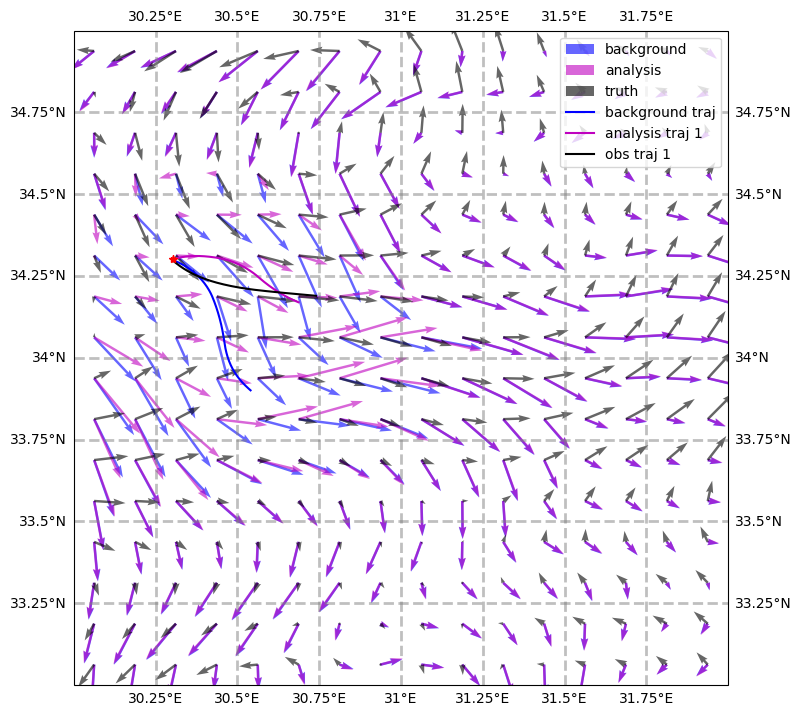

In [16]:
if METHOD == "standard":
    from plots import display_window_new

    iwindow = 1   # which correction window to display (1 … n_corr)
    assert 1 <= iwindow <= n_corr, f"iwindow must be in [1, {n_corr}]"

    display_window_new(
        iwindow, LON, LAT,
        Ut, Vt, Ub, Vb, lon, lat,
        mainh5, nDaysSim, n_drif,
        lfil, alpha, beta, toll, mylr,
    )
else:
    print("Quiver plot via display_window_new is only available for METHOD='standard'.")
    print("See §6d for the sliding-window velocity comparison.")

### 6b · Optimisation loss curve

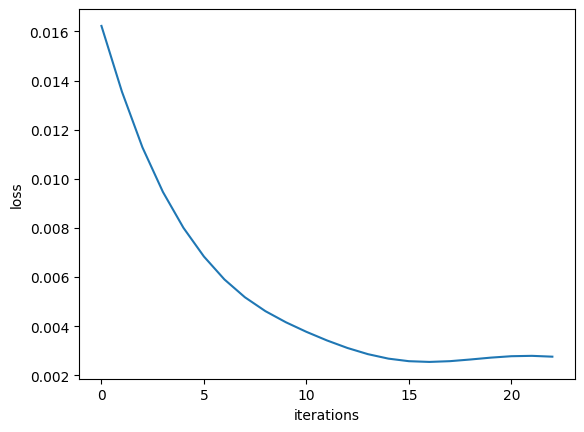

In [17]:
if METHOD == "standard":
    from plots import display_loss_new

    iwindow = 1   # which correction window's loss to display (1 … n_corr)
    assert 1 <= iwindow <= n_corr, f"iwindow must be in [1, {n_corr}]"

    display_loss_new(mainh5, iwindow, nDaysSim, lfil, alpha, beta, toll, mylr)
else:
    print("Loss curve (display_loss_new) is only available for METHOD='standard'.")

### 6c · RMSE as a function of time

In [ ]:
from plots import display_rmse

# Keys written by both methods; adjust if your plot routine differs
try:
    display_rmse(mainh5, nDaysSim, lfil, alpha, beta, toll, mylr, Tw_days, sigma_days)
except Exception as e:
    print(f"Could not plot RMSE: {e}")
    print("Check that display_rmse accepts an open HDF5 handle and the parameter set above.")

Could not plot RMSE: display_rmse() missing 2 required positional arguments: 'Tw_days' and 'sigma_days'
Check that display_rmse accepts an open HDF5 handle and the parameter set above.


### 6d · Velocity comparison — sliding window

Shows background (blue), truth (black), and corrected (purple) fields.  
*Only meaningful after running `METHOD = "sliding"`.*

In [ ]:
if METHOD == "sliding" and Uc is not None:
    Ub_avg = np.mean(Ub.detach().numpy(), axis=0).T
    Vb_avg = np.mean(Vb.detach().numpy(), axis=0).T
    Ut_avg = np.mean(Ut.detach().numpy(), axis=0).T
    Vt_avg = np.mean(Vt.detach().numpy(), axis=0).T
    Uc_avg = np.mean(Uc.detach().numpy(), axis=0).T
    Vc_avg = np.mean(Vc.detach().numpy(), axis=0).T

    x = lon.detach().numpy()
    y = lat.detach().numpy()

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.quiver(x, y, Ub_avg, Vb_avg, color="steelblue",  label="Background")
    ax.quiver(x, y, Ut_avg, Vt_avg, color="black",      label="Truth")
    ax.quiver(x, y, Uc_avg, Vc_avg, color="mediumpurple",label="Corrected")
    ax.set_xlabel("Longitude (E)")
    ax.set_ylabel("Latitude (N)")
    ax.set_title("Sliding-window assimilation — time-averaged currents")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Run §5 with METHOD='sliding' first.")

## 7 · Finalise

In [ ]:
mainh5.close()
print(f"Results saved to {out_dir / (exp_name + '.h5')}")